In [ ]:
!pip install medmnist timm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 10.6 MB/s eta 0:00:00


Using device: cuda
Classi nel Train Set -> Maligni (0): 147, Benigni (1): 399
Epoch 1/20 - Train Loss: 0.5381 | Val Loss: 0.4078 | Val F1: 0.7934 | Val AUC: 0.5848
Epoch 2/20 - Train Loss: 0.4806 | Val Loss: 0.3874 | Val F1: 0.7759 | Val AUC: 0.6115
Epoch 3/20 - Train Loss: 0.4380 | Val Loss: 0.3610 | Val F1: 0.7048 | Val AUC: 0.6416
Epoch 4/20 - Train Loss: 0.4409 | Val Loss: 0.3719 | Val F1: 0.8136 | Val AUC: 0.6583
Epoch 5/20 - Train Loss: 0.4361 | Val Loss: 0.3517 | Val F1: 0.7857 | Val AUC: 0.6792
Epoch 6/20 - Train Loss: 0.3924 | Val Loss: 0.3575 | Val F1: 0.8103 | Val AUC: 0.6926
Epoch 7/20 - Train Loss: 0.4199 | Val Loss: 0.3468 | Val F1: 0.7895 | Val AUC: 0.7076
Epoch 8/20 - Train Loss: 0.3869 | Val Loss: 0.3369 | Val F1: 0.7928 | Val AUC: 0.7168
Epoch 9/20 - Train Loss: 0.3963 | Val Loss: 0.3281 | Val F1: 0.7664 | Val AUC: 0.7243
Epoch 10/20 - Train Loss: 0.4052 | Val Loss: 0.3270 | Val F1: 0.7706 | Val AUC: 0.7285
Epoch 11/20 - Train Loss: 0.3706 | Val Loss: 0.3306 | Val F1:

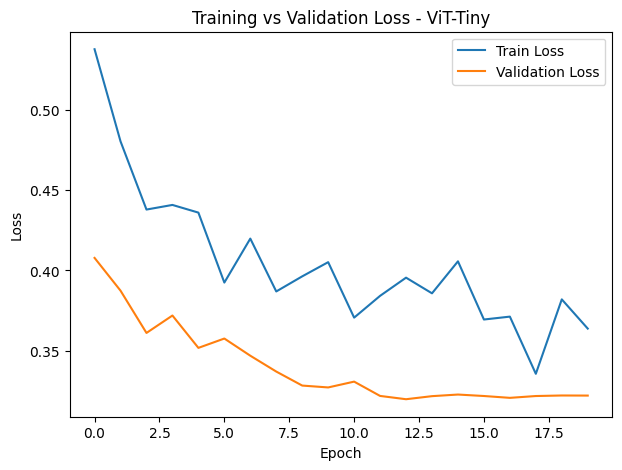


--- RISULTATI FINALI TEST SET (ViT-Tiny) ---
Accuracy:              0.7372
F1-Score:              0.8128 (Benign)
AUC-ROC:               0.7594
Sensitivity Malignant: 0.6190
Sensitivity Benign:    0.7807


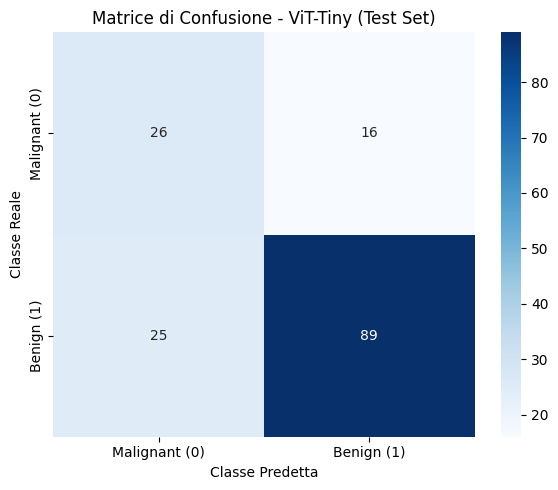

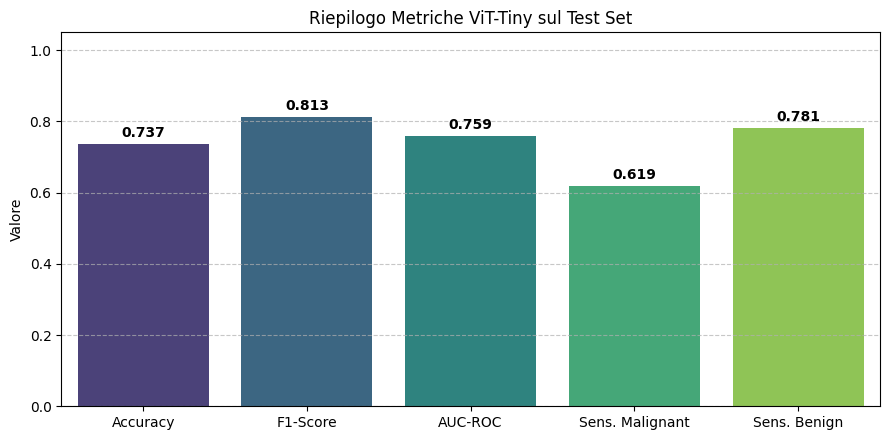

Totale immagini classificate erroneamente: 41 su 156


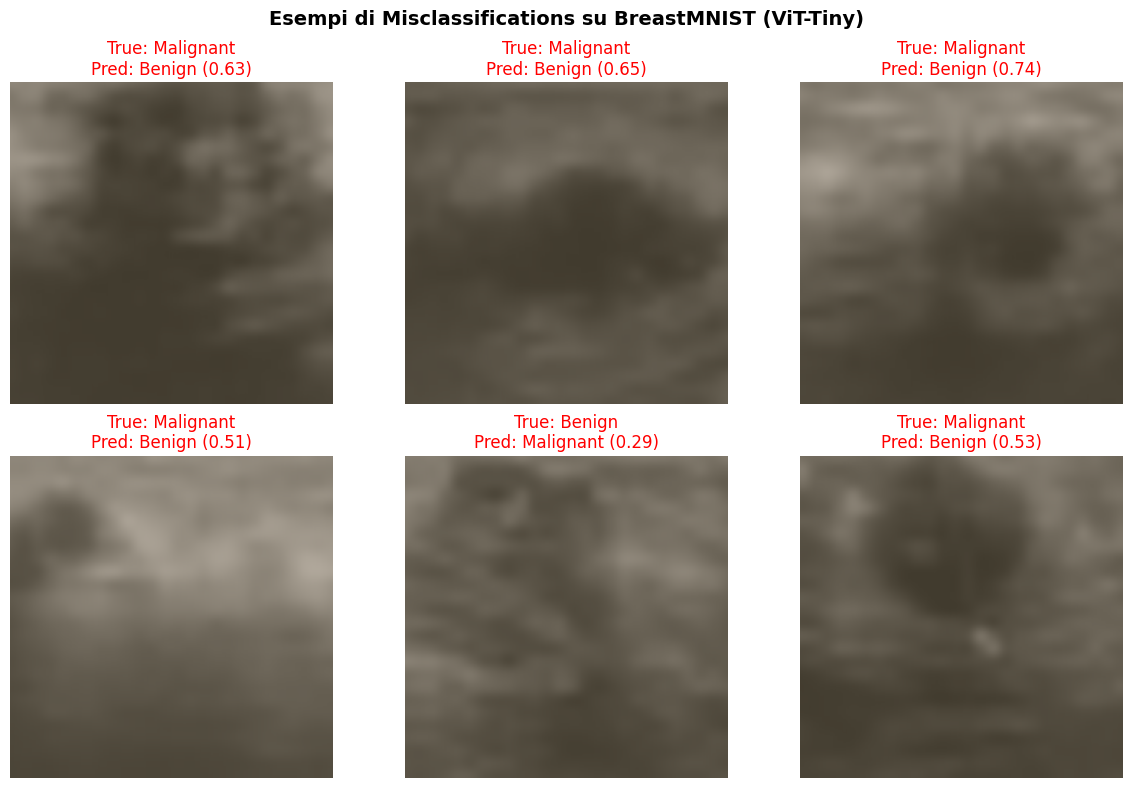

In [ ]:
import os
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import medmnist
from medmnist import INFO
import matplotlib.pyplot as plt
import seaborn as sns
import timm

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

data_flag = 'breastmnist'
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

BATCH_SIZE = 32
NUM_EPOCHS = 20

# Data Augmentation )
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

#train_transform = transforms.Compose([
    #transforms.Resize((224, 224)),
    #transforms.RandomHorizontalFlip(),
    #transforms.RandomRotation(15),
    #transforms.ToTensor(),
    #transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
#])

#val_test_transform = transforms.Compose([
    #transforms.Resize((224, 224)),
    #transforms.ToTensor(),
    #transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
#])



model = timm.create_model('vit_tiny_patch16_224', pretrained=True)

# trasformazioni automatiche ed ottimali di timm
data_config = timm.data.resolve_model_data_config(model)

train_transform = timm.data.create_transform(**data_config, is_training=True)
val_test_transform = timm.data.create_transform(**data_config, is_training=False)



train_dataset = DataClass(split='train', transform=train_transform, download=True, as_rgb=True)
val_dataset = DataClass(split='val', transform=val_test_transform, download=True, as_rgb=True)
test_dataset = DataClass(split='test', transform=val_test_transform, download=True, as_rgb=True)

train_loader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(dataset=test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Gestione Sbilanciamento Classi (Classe 0: Maligno, Classe 1: Benigno)
train_labels = train_dataset.labels.flatten()
num_malignant = np.sum(train_labels == 0)
num_benign = np.sum(train_labels == 1)
print(f"Classi nel Train Set -> Maligni (0): {num_malignant}, Benigni (1): {num_benign}")

pos_weight_val = torch.tensor([num_malignant / num_benign], dtype=torch.float).to(device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_val)

# Sostituiamo la testa lineare per la classificazione binaria
num_ftrs = model.head.in_features
model.head = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(num_ftrs, 1)
)

# Sblocchiamo TUTTI i parametri
for param in model.parameters():
    param.requires_grad = True

model = model.to(device)

# Separiamo i parametri della backbone da quelli della testa
backbone_params = [p for n, p in model.named_parameters() if 'head' not in n]
head_params = model.head.parameters()

# Configuriamo l'ottimizzatore con Learning Rate differenti
optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': 1e-5},  # LR molto basso per preservare i pesi pre-addestrati
    {'params': head_params, 'lr': 3e-4}       # LR standard per la nuova testa
], weight_decay=1e-2)


scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

# Loop di Training e Validazione
best_val_loss = float('inf')
best_model_wts = copy.deepcopy(model.state_dict())

train_losses = []
val_losses = []
val_f1s = []
val_aucs = []

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    for inputs, targets in train_loader:
        inputs = inputs.to(device)
        targets = targets.to(device).float()

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)
    scheduler.step()

    # Validazione
    model.eval()
    val_loss = 0.0
    val_targets_all = []
    val_preds_all = []

    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs = inputs.to(device)
            targets = targets.to(device).float()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)

            probs = torch.sigmoid(outputs)
            val_targets_all.extend(targets.cpu().numpy())
            val_preds_all.extend(probs.cpu().numpy())

    val_loss /= len(val_loader.dataset)
    val_preds_class = (np.array(val_preds_all) >= 0.5).astype(int)
    val_f1 = f1_score(val_targets_all, val_preds_class)
    val_auc = roc_auc_score(val_targets_all, val_preds_all)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_f1s.append(val_f1)
    val_aucs.append(val_auc)

    print(f"Epoch {epoch+1}/{NUM_EPOCHS} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f} | Val AUC: {val_auc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())

# Ricarichiamo i pesi del miglior modello
model.load_state_dict(best_model_wts)

# Grafico Loss
plt.figure(figsize=(7,5))
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss - ViT-Tiny')
plt.legend()
plt.show()

# Valutazione Finale sul Test Set
model.eval()
test_targets_all = []
test_preds_all = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        probs = torch.sigmoid(outputs)
        test_targets_all.extend(targets.numpy())
        test_preds_all.extend(probs.cpu().numpy())

test_targets_all = np.array(test_targets_all)
test_preds_all = np.array(test_preds_all)
test_preds_class = (test_preds_all >= 0.5).astype(int)

# Metriche
acc = accuracy_score(test_targets_all, test_preds_class)
f1 = f1_score(test_targets_all, test_preds_class)
auc = roc_auc_score(test_targets_all, test_preds_all)

cm = confusion_matrix(test_targets_all, test_preds_class)
tn, fp, fn, tp = cm.ravel()

sensitivity_malignant = tn / (tn + fp)
sensitivity_benign = tp / (tp + fn)

print("\n--- RISULTATI FINALI TEST SET (ViT-Tiny) ---")
print(f"Accuracy:              {acc:.4f}")
print(f"F1-Score:              {f1:.4f} (Benign)")
print(f"AUC-ROC:               {auc:.4f}")
print(f"Sensitivity Malignant: {sensitivity_malignant:.4f}")
print(f"Sensitivity Benign:    {sensitivity_benign:.4f}")

# Visualizzazione Matrice di Confusione
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.title('Matrice di Confusione - ViT-Tiny (Test Set)')
plt.ylabel('Classe Reale')
plt.xlabel('Classe Predetta')
plt.tight_layout()
plt.show()

# Visualizzazione Riepilogo Metriche
metrics_name = ['Accuracy', 'F1-Score', 'AUC-ROC', 'Sens. Malignant', 'Sens. Benign']
metrics_val = [acc, f1, auc, sensitivity_malignant, sensitivity_benign]

plt.figure(figsize=(9, 4.5))
sns.barplot(x=metrics_name, y=metrics_val, palette='viridis', hue=metrics_name, legend=False)
plt.ylim(0, 1.05)
for i, val in enumerate(metrics_val):
    plt.text(i, val + 0.02, f"{val:.3f}", ha='center', fontweight='bold')
plt.title('Riepilogo Metriche ViT-Tiny sul Test Set')
plt.ylabel('Valore')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Analysis delle Misclassificazioni
y_true = test_targets_all.flatten()
y_pred = test_preds_class.flatten()
y_prob = test_preds_all.flatten()

misclassified_indices = np.where(y_pred != y_true)[0]
print(f"Totale immagini classificate erroneamente: {len(misclassified_indices)} su {len(y_true)}")

if len(misclassified_indices) > 0:
    plt.figure(figsize=(12, 8))
    num_to_show = min(6, len(misclassified_indices))

    mean_np = np.array([0.485, 0.456, 0.406])
    std_np = np.array([0.229, 0.224, 0.225])

    for idx, mis_idx in enumerate(misclassified_indices[:num_to_show]):
        img, label = test_dataset[mis_idx]

        img_np = img.permute(1, 2, 0).numpy()
        img_np = (img_np * std_np) + mean_np
        img_np = np.clip(img_np, 0, 1)

        pred_label = y_pred[mis_idx]
        prob = y_prob[mis_idx]
        real_label = int(label[0]) if hasattr(label, '__len__') else int(label)

        plt.subplot(2, 3, idx + 1)
        plt.imshow(img_np)

        real_str = "Benign" if real_label == 1 else "Malignant"
        pred_str = "Benign" if pred_label == 1 else "Malignant"

        plt.title(f"True: {real_str}\nPred: {pred_str} ({prob:.2f})", color='red')
        plt.axis('off')

    plt.suptitle("Esempi di Misclassifications su BreastMNIST (ViT-Tiny)", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print("Nessun errore di classificazione trovato!")